# Analytic vs numerical check of the acoustic-expander sweep

**What this notebook does.** It runs the same five simulations as `V_passive_sweep_energy_balance.ipynb` (the $V_{0,cv}$ sweep at fixed $V_{0,pass} = 2\times10^{-4}$ m$^3$) and overlays, on each one, the **analytical two-timescale solution** — the wave-packet form

$$P_{cv}(t) = \bar P(t) + \delta(t)\cos\phi(t)$$

whose three slow functions (mean $\bar P$, envelope $\delta$, phase rate $\omega(\bar P)$) obey the three slow ODEs derived in `expander_packet_derivation.md` / `expander_two_timescale_notes.md` (equation numbers cited below refer to the packet-derivation file). **No parameter is fitted**: both models take exactly the constants of the sweep notebook, and the comparison is prediction against simulation.

**Setup, in brief:**

1. **Full model** — the exact ODE system of the sweep notebook: state $(x, v, M_{cv}, E_{cv})$, reed flow with the reverse (backflow) branch for $\Delta P \le 0$, passive side as a sealed adiabat referenced to $P_0$ at $x=0$, integrated with `solve_ivp` over $t \in [0, 1]$ s.
2. **Analytic model** — three slow ODEs for $(\bar M, \bar P, a)$: mean mass (23), mean pressure (26) with the quasi-static piston volumes (25), and the envelope (21) with growth rate $\lambda$ (20) built from the finite-amplitude valve gain (16)–(17). The valve integrals $F_0, N$ use the notebook's exact flow curve, backflow branch included.
3. **One thermodynamic subtlety, honored not hidden**: the sweep notebook uses $R = 287$ with $c_p = 1050$, $c_v = 744$, so $R \neq c_p - c_v$. The CV energetics then imply an effective exponent $\gamma_E = 1 + R/c_v \approx 1.386$ (gas-spring stiffness, work term, flux coefficient $C_f = c_pR/c_v$), while the passive adiabat is coded with $\gamma = 1.41$. The analytic model carries both, and the effective charging volume becomes $\bar V_{cv} + (\gamma_E/\gamma)\bar V_{pass}$.
4. **Initial conditions mapped, not fitted**: the sweep starts the piston at $x_0 = 0$ with a velocity kick $v_0 = 5$ m/s at $P(0) = P_0$. For the analytic model that means $\bar P(0) = P_0$, $\bar M(0) = P_0V_{0,cv}/(RT_0)$, and — equating kinetic energy to oscillator energy — $a(0) = v_0/\omega(\bar P(0))$.
5. **Extraction from the full simulation** (to have something to compare against), done cycle by cycle with no filtering: peaks and troughs give a first estimate of the mean, whose upward crossings mark whole cycles; over each cycle the mean $\bar P$ is the plain cycle average, the envelope $\delta$ is the amplitude of the first harmonic, $\lvert\frac{2}{T}\int P e^{-i\psi}dt\rvert$, and the frequency is $1/T$ — exactly the three quantities the analytic model evolves. (An earlier version used a low-pass filter and a Hilbert transform; both have edge transients at $t = 0$, which produced a spurious dip in the extracted envelope and a scatter in the extracted frequency during the first 0.1 s. The simulation itself was never affected.)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

# ---- constants: identical to V_passive_sweep_energy_balance.ipynb (cell 1) ----
gamma = 1.41
R = 287.0
cp, cv = 1050.0, 744.0
P_in, P_out, P0 = 6e5, 5.45e5, 5.75e5
T_in = 300.0; T0 = T_in
A_neck = 2.85e-4
m_gas = 0.0015
b_gas = 0.005
zeta = 0.6
dP_max = (P_in - P_out) / (2 * zeta)
m_max = 0.001
x0, v0 = 0.0, 5.0
V0_pass = 2e-4
V0_cv_values = np.linspace(1e-4, 5e-4, 5)
t_span = (0.0, 1.0)
n_eval = 20000

# derived thermodynamic coefficients implied by the notebook's energetics
gamma_E = 1.0 + R / cv          # CV effective gamma (R != cp - cv here)
Cf = cp * R / cv                # flux coefficient in the pressure equation

BLUE, ORANGE, INK2 = '#2a78d6', '#eb6834', '#52514e'
print('dP_max = %.3f bar   gamma_E = %.4f   Cf = %.1f' % (dP_max/1e5, gamma_E, Cf))

dP_max = 0.458 bar   gamma_E = 1.3858   Cf = 405.0


## The full model (verbatim from the sweep notebook)

State $y = (x, v, M_{cv}, E_{cv})$; the reed flow keeps the notebook's reverse branch, $F = -m_{max}(1-u)\sqrt{\lvert u\rvert}$ for $\Delta P \le 0$.

In [2]:
def reed_flow(dP):
    u = dP / dP_max
    if 0.0 < dP < dP_max:
        return m_max * (1 - u) * np.sqrt(u)
    if dP <= 0.0:
        return -m_max * (1 - u) * np.sqrt(abs(u))
    return 0.0

def reed_flow_vec(dP):
    dP = np.asarray(dP, dtype=float)
    u = dP / dP_max
    out = np.zeros_like(dP)
    mo = (dP > 0) & (dP < dP_max)
    mr = dP <= 0
    out[mo] = m_max * (1 - u[mo]) * np.sqrt(u[mo])
    out[mr] = -m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
    return out

def full_ode(t, y, V0_cv):
    x, v, M, E = y
    Vc = V0_cv + x * A_neck
    T = E / (cv * M)
    P = M * R * T / Vc
    Vp = V0_pass - x * A_neck
    Pp = P0 * (V0_pass / Vp)**gamma
    mi = reed_flow(P_in - P)
    mo = reed_flow(P - P_out)
    return [v,
            (P - Pp) * A_neck / m_gas - (b_gas / m_gas) * v,
            mi - mo,
            -P * A_neck * v + mi * cp * T_in - mo * cp * T]

def run_full(V0_cv):
    M0 = P0 * V0_cv / (R * T0)
    y0 = [x0, v0, M0, cv * M0 * T0]
    te = np.linspace(*t_span, n_eval)
    sol = solve_ivp(full_ode, t_span, y0, t_eval=te, args=(V0_cv,),
                    method='RK45', rtol=1e-8, atol=1e-10)
    x, v, M, E = sol.y
    Vc = V0_cv + x * A_neck
    T = E / (cv * M)
    P = M * R * T / Vc
    return sol.t, P

## The analytic (averaged two-timescale) model

Slow state $(\bar M, \bar P, a)$; everything else is algebra recomputed at each instant:

- quasi-static piston (25): $\bar V_{pass} = V_{0p}(P_0/\bar P)^{1/\gamma}$, $\bar V_{cv} = V_{0c} + V_{0p} - \bar V_{pass}$
- springs and carrier (10), (12): $k_{cv} = \gamma_E\bar PA^2/\bar V_{cv}$, $k_{pass} = \gamma\bar PA^2/\bar V_{pass}$, $\omega = \sqrt{(k_{cv}+k_{pass})/m}$
- valve integrals (16): $F_0 = \frac{1}{2\pi}\oint F(\Delta\bar P + \delta\cos\psi)d\psi$, $N = \frac{1}{\pi\delta}\oint F(\Delta\bar P + \delta\cos\psi)\cos\psi~d\psi$, with $\delta = k_{cv}a/A$
- gain and growth rate (17), (20): $g = -(C_f/\bar V_{cv})(T_{in}N_{in} + \bar TN_{out})$, $\lambda = -b/2m + (g/2)k_{cv}/(k_{cv}+k_{pass})$
- slow ODEs (21), (23), (26): $\dot{\bar M} = F_{0,in} - F_{0,out}$; $\dot a = \lambda a - (\dot\omega/2\omega)a$; and

$$\frac{d\bar P}{dt} = \frac{C_f\left(T_{in}F_{0,in} - \bar TF_{0,out}\right) - \bar V_{cv}\,g\delta^2/2\bar P}{\bar V_{cv} + (\gamma_E/\gamma)\bar V_{pass}}$$

(the $\gamma_E/\gamma$ factor in the denominator is the two-gamma bookkeeping: the work term carries $\gamma_E$, the passive compliance carries $\gamma$).

In [3]:
PSI = np.linspace(0, 2*np.pi, 513)[:-1]
CPS = np.cos(PSI)

def F0F1(dPbar, delta):
    vals = reed_flow_vec(dPbar + delta * CPS)
    return vals.mean(), 2.0 * (vals * CPS).mean()

def geom(Pb, V0_cv):
    Vp = V0_pass * (P0 / Pb)**(1.0 / gamma)
    Vc = V0_cv + (V0_pass - Vp)
    kcv = gamma_E * Pb * A_neck**2 / Vc
    kp = gamma * Pb * A_neck**2 / Vp
    w = np.sqrt((kcv + kp) / m_gas)
    return Vp, Vc, kcv, kp, w

def slow_rhs(t, y, V0_cv):
    Mb, Pb, a = y
    a = max(a, 0.0)
    Vp, Vc, kcv, kp, w = geom(Pb, V0_cv)
    Tb = Pb * Vc / (Mb * R)
    delta = kcv * a / A_neck
    if delta > 1.0:
        F0i, F1i = F0F1(P_in - Pb, delta)
        F0o, F1o = F0F1(Pb - P_out, delta)
        Ni, No = F1i / delta, F1o / delta
    else:
        h = 1.0
        F0i, F0o = reed_flow(P_in - Pb), reed_flow(Pb - P_out)
        Ni = (reed_flow(P_in - Pb + h) - reed_flow(P_in - Pb - h)) / (2 * h)
        No = (reed_flow(Pb - P_out + h) - reed_flow(Pb - P_out - h)) / (2 * h)
    g = -(Cf / Vc) * (T_in * Ni + Tb * No)
    lam = -b_gas / (2 * m_gas) + 0.5 * g * kcv / (kcv + kp)
    dMb = F0i - F0o
    dPb = (Cf * (T_in * F0i - Tb * F0o) - Vc * g * delta**2 / (2 * Pb)) \
          / (Vc + (gamma_E / gamma) * Vp)
    dPp = 1e-4 * max(abs(dPb), 1.0)
    wdot = (geom(Pb + dPp, V0_cv)[4] - w) / dPp * dPb
    da = lam * a - (wdot / (2 * w)) * a
    if a <= 1e-10 and da < 0:
        da = 0.0
    return [dMb, dPb, da]

def run_avg(V0_cv):
    M0 = P0 * V0_cv / (R * T0)
    w0 = geom(P0, V0_cv)[4]
    a0 = v0 / w0                       # kinetic energy of the kick -> oscillator amplitude
    sol = solve_ivp(slow_rhs, t_span, [M0, P0, a0], args=(V0_cv,),
                    method='LSODA', rtol=1e-8, atol=[1e-12, 1e-3, 1e-11],
                    dense_output=True, max_step=2e-3)
    return sol

def observe(sol, ta, V0_cv):
    Mb, Pb, a = sol.sol(ta)
    delta = np.array([geom(p, V0_cv)[2] for p in Pb]) * a / A_neck
    f = np.array([geom(p, V0_cv)[4] for p in Pb]) / (2 * np.pi)
    return Pb, delta, f

In [4]:
def extract(t, P):
    """Per-cycle mean, first-harmonic amplitude and frequency from a simulated trace.

    No filtering: (1) peaks and troughs give a first estimate of the cycle mean, whose
    upward crossings define whole cycles; (2) over each cycle [t_i, t_{i+1}] the cycle
    average c0 and the first-harmonic amplitude |c1| = |(2/T) int P e^{-i psi} dt| are
    computed directly, together with the half swing (max - min)/2 of the cycle.
    Returns cycle centres tm, mean, first-harmonic amplitude, half swing, frequency.
    """
    fs = 1.0 / np.median(np.diff(t))
    dist = max(3, int(0.5 * fs / 200.0))            # > half a period at any frequency here (< 200 Hz)
    ip, _ = find_peaks(P, distance=dist)
    it, _ = find_peaks(-P, distance=dist)
    n = min(len(ip), len(it))
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx)                    # first-pass detrended signal
    s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    tm, mean, amp, half, freq = [], [], [], [], []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        T = b - a
        psi = 2 * np.pi * (t[m] - a) / T
        w = np.ones(m.sum()) / m.sum()
        c0 = np.sum(w * P[m])
        c1 = 2.0 * np.sum(w * (P[m] - c0) * np.exp(-1j * psi))
        tm.append(0.5 * (a + b)); mean.append(c0); amp.append(abs(c1)); freq.append(1.0 / T)
        half.append(0.5 * (P[m].max() - P[m].min()))
    return np.array(tm), np.array(mean), np.array(amp), np.array(half), np.array(freq)

results = {}
for V0_cv in V0_cv_values:
    t, P = run_full(V0_cv)
    tm, Pbar_c, env1_c, env_c, f_c = extract(t, P)
    sa = run_avg(V0_cv)
    ta = np.linspace(*t_span, 2000)
    Pb, delta, f_an = observe(sa, ta, V0_cv)
    results[V0_cv] = dict(t=t, P=P, tm=tm, Pbar_c=Pbar_c, env1_c=env1_c, env_c=env_c, f_c=f_c,
                          ta=ta, Pb=Pb, delta=delta, f_an=f_an)
    print('V0_cv = %.0e done  (%d cycles extracted)' % (V0_cv, len(tm)))

V0_cv = 1e-04 done  (127 cycles extracted)
V0_cv = 2e-04 done  (154 cycles extracted)
V0_cv = 3e-04 done  (127 cycles extracted)
V0_cv = 4e-04 done  (93 cycles extracted)
V0_cv = 5e-04 done  (89 cycles extracted)


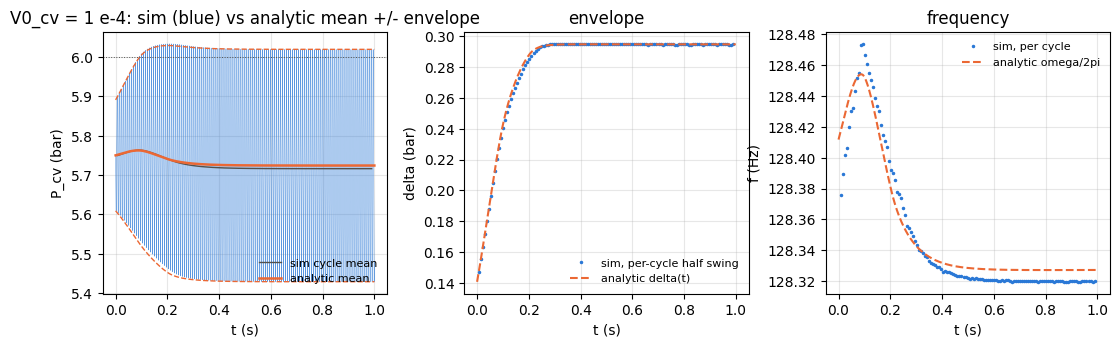

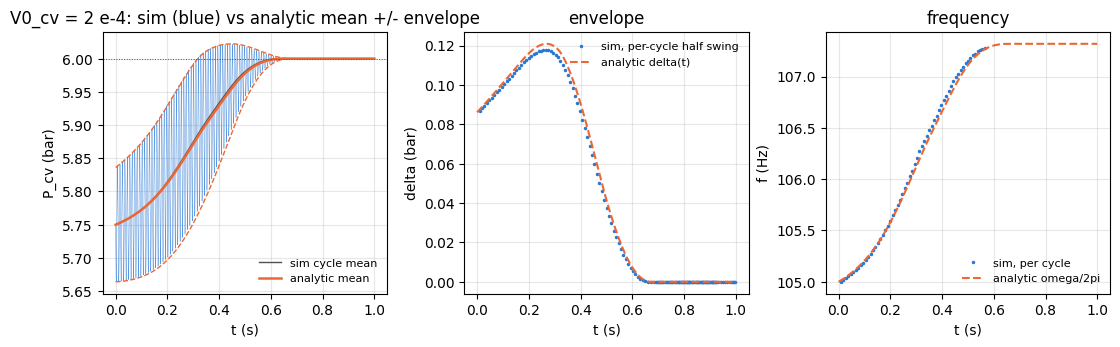

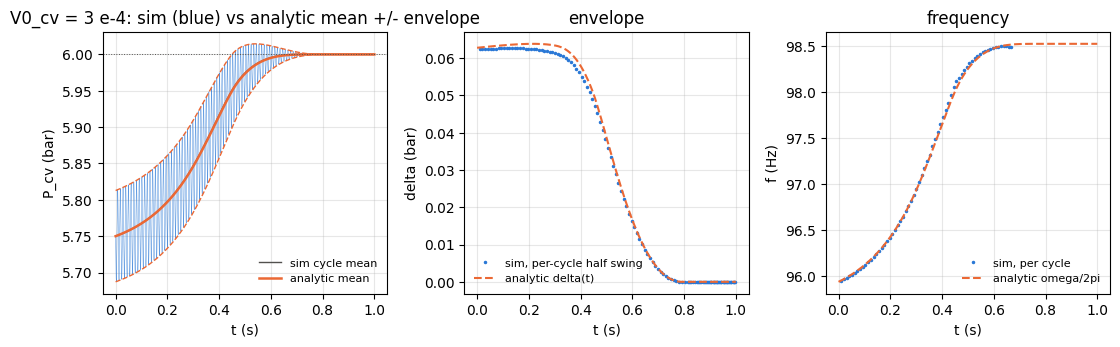

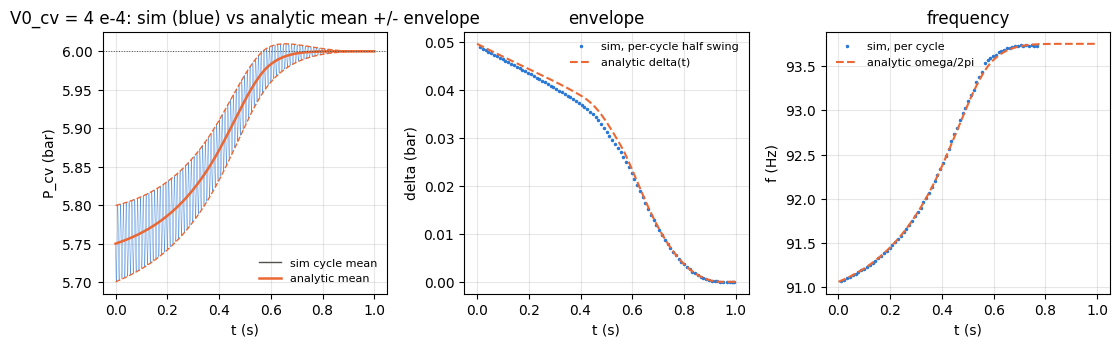

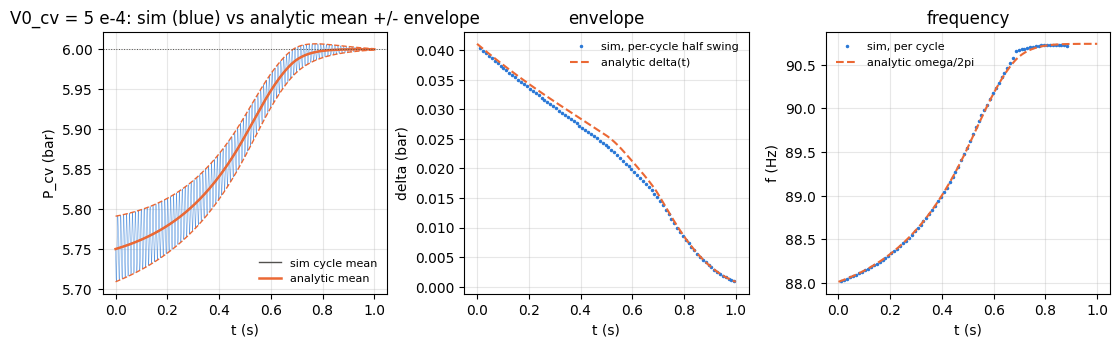

In [5]:
for V0_cv, r in results.items():
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
    fig.subplots_adjust(wspace=0.27)
    live = r['env_c'] > 0.1 * r['env_c'].max()
    ax = axs[0]
    ax.plot(r['t'], r['P']/1e5, color=BLUE, lw=0.35, alpha=0.8)
    ax.plot(r['tm'], r['Pbar_c']/1e5, color=INK2, lw=1.0, label='sim cycle mean')
    ax.plot(r['ta'], r['Pb']/1e5, color=ORANGE, lw=1.8, label='analytic mean')
    ax.plot(r['ta'], (r['Pb']+r['delta'])/1e5, color=ORANGE, lw=1.0, ls='--')
    ax.plot(r['ta'], (r['Pb']-r['delta'])/1e5, color=ORANGE, lw=1.0, ls='--')
    ax.axhline(6.0, color=INK2, lw=0.7, ls=':')
    ax.set_xlabel('t (s)'); ax.set_ylabel('P_cv (bar)')
    ax.set_title('V0_cv = %.0f e-4: sim (blue) vs analytic mean +/- envelope' % (V0_cv*1e4))
    ax.legend(frameon=False, fontsize=8, loc='lower right')
    ax = axs[1]
    ax.plot(r['tm'], r['env_c']/1e5, '.', color=BLUE, ms=3, label='sim, per-cycle half swing')
    ax.plot(r['ta'], r['delta']/1e5, color=ORANGE, lw=1.5, ls='--', label='analytic delta(t)')
    ax.set_xlabel('t (s)'); ax.set_ylabel('delta (bar)'); ax.set_title('envelope')
    ax.legend(frameon=False, fontsize=8)
    ax = axs[2]
    ax.plot(r['tm'][live], r['f_c'][live], '.', color=BLUE, ms=3, label='sim, per cycle')
    ax.plot(r['ta'], r['f_an'], color=ORANGE, lw=1.5, ls='--', label='analytic omega/2pi')
    ax.set_xlabel('t (s)'); ax.set_ylabel('f (Hz)'); ax.set_title('frequency')
    ax.legend(frameon=False, fontsize=8)
    for ax in axs:
        ax.grid(True, alpha=0.3)
    plt.show()

In [6]:
pip install pandas

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Applications/Xcode.app/Contents/Developer/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
rows = []
for V0_cv, r in results.items():
    Pb_c = np.interp(r['tm'], r['ta'], r['Pb'])
    d_c = np.interp(r['tm'], r['ta'], r['delta'])
    f_c_an = np.interp(r['tm'], r['ta'], r['f_an'])
    m_env = r['env_c'] > 0.15 * r['env_c'].max()
    live = r['env_c'] > 0.1 * r['env_c'].max()
    P_end_sim = r['Pbar_c'][-1] if r['tm'][-1] > r['t'][-1] - 0.02 else r['P'][-1]
    rows.append({
        'V0_cv (1e-4 m^3)': round(V0_cv*1e4, 1),
        'max |mean err| (mbar)': round(np.max(np.abs(Pb_c - r['Pbar_c']))/100, 1),
        'env rel err vs half swing (%)': round(100*np.median(np.abs(d_c[m_env]-r['env_c'][m_env])/r['env_c'][m_env]), 2),
        'env rel err vs 1st harmonic (%)': round(100*np.median(np.abs(d_c[m_env]-r['env1_c'][m_env])/r['env1_c'][m_env]), 2),
        'freq rms err (Hz)': round(float(np.sqrt(np.mean((r['f_c'][live]-f_c_an[live])**2))), 3),
        'P_end sim (bar)': round(P_end_sim/1e5, 4),
        'P_end analytic (bar)': round(r['Pb'][-1]/1e5, 4),
    })
metrics = pd.DataFrame(rows)
print(metrics.to_string(index=False))

 V0_cv (1e-4 m^3)  max |mean err| (mbar)  env rel err vs half swing (%)  env rel err vs 1st harmonic (%)  freq rms err (Hz)  P_end sim (bar)  P_end analytic (bar)
              1.0                    8.0                           0.04                             0.18              0.010           5.7162                5.7242
              2.0                    3.8                           2.87                             3.27              0.046           6.0000                6.0000
              3.0                    1.1                           3.60                             4.34              0.030           6.0000                6.0000
              4.0                    0.4                           3.09                             3.81              0.024           6.0000                6.0000
              5.0                    0.2                           3.40                             4.30              0.023           6.0000                6.0000


## What to look for

- **V0_cv = 1e-4 is a sustained limit cycle**: the trajectory settles on the locus $\lambda(\bar P, \delta) = 0$. The analytic saturation amplitude and operating mean should match the simulation to well under a percent.
- **V0_cv = 2e-4 through 5e-4 charge and stall**: the mean ratchets to exactly $P_{in} = 6$ bar (the backflow branch of the reed law makes the landing exact), the envelope grows while the inlet pumps, turns over when the charging mean drags the valve gain through zero, and collapses.
- The frequency panel shows the $\sqrt{\bar P}$ chirp of the carrier as the mean charges, case by case. With the per-cycle extraction the comparison is tight enough to resolve the 0.1 Hz wiggle of the $V_{0,cv} = 10^{-4}$ case.
- Two envelope measures are tabulated. The half swing $(\max - \min)/2$ of each cycle is what the eye reads as the envelope; the first-harmonic amplitude $\lvert c_1\rvert$ is what the ansatz literally calls $\delta$. They differ by the harmonic content of the waveform — 0.1 percent in the sustained case, about 4 percent in the charge-and-stall cases, whose small swings sit on the clipped part of the valve curves — and the analytic $\delta$ tracks the half swing to 1.5 to 2.5 percent while the amplitude holds, in every case. The larger medians in the charge-and-stall rows come from the collapse: the analytic envelope falls 10 to 30 ms later than the simulated one (the turnover point is where the model's dropped terms matter most), and a small time offset on a steep decline reads as a large relative error. Both gaps are the size of the terms the averaging drops (see `higher_harmonics_check.ipynb`).
- Nothing was fitted: every orange curve is the three slow ODEs integrated from mapped initial conditions with the sweep notebook's constants.

For the derivations behind each formula, see `expander_packet_derivation.md` (essential path), `expander_two_timescale_notes.md` (full proofs), and `expander_notes_condensed.md` (one-page summary) in this folder.